In [ ]:
%reload_ext autoreload
%autoreload 2

In [ ]:
import os

os.environ['CUDA_VISIBLE_DEVICES'] = '1'
os.environ['XLA_PYTHON_CLIENT_MEM_FRACTION'] = '1'

In [ ]:
import jax.numpy as jnp
import numpy as np
from scipy.stats import qmc
from scipy.stats import t as stuent_t
import matplotlib.pyplot as plt
from corner import corner, overplot_lines, overplot_points

from utils.linear_model import get_ODR, get_OLS, xy2logxy

In [ ]:
k = 1.3
b = 0.1
sig = 0.2
N = 10000

x = np.random.uniform(0.1, 10, size=N)

y = 10**(k * np.log10(x) + b + np.random.normal(0, sig, size=N))
# add outliers
selected = np.random.choice(N, 1000, replace=False)
y[selected] = 10**(-k * np.log10(x[selected]) + b +
                   np.random.normal(0, sig, size=1000))

x_err = np.random.uniform(0.1, 0.5, size=N)
x_obs = np.random.normal(x, x_err)

y_err = np.random.uniform(0.1, 0.5, size=N)
y_obs = np.random.normal(y, y_err)

x_err = jnp.asarray(x_err)
x_obs = jnp.asarray(x_obs)
y_err = jnp.asarray(y_err)
y_obs = jnp.asarray(y_obs)

In [ ]:
logx_obs, logy_obs, logx_err, logy_err = xy2logxy(x_obs, y_obs, x_err, y_err)

In [ ]:
res_ODR = get_ODR(logx_obs, logy_obs)
res_OLS = get_OLS(logx_obs, logy_obs)

(-50.0, 100.0)

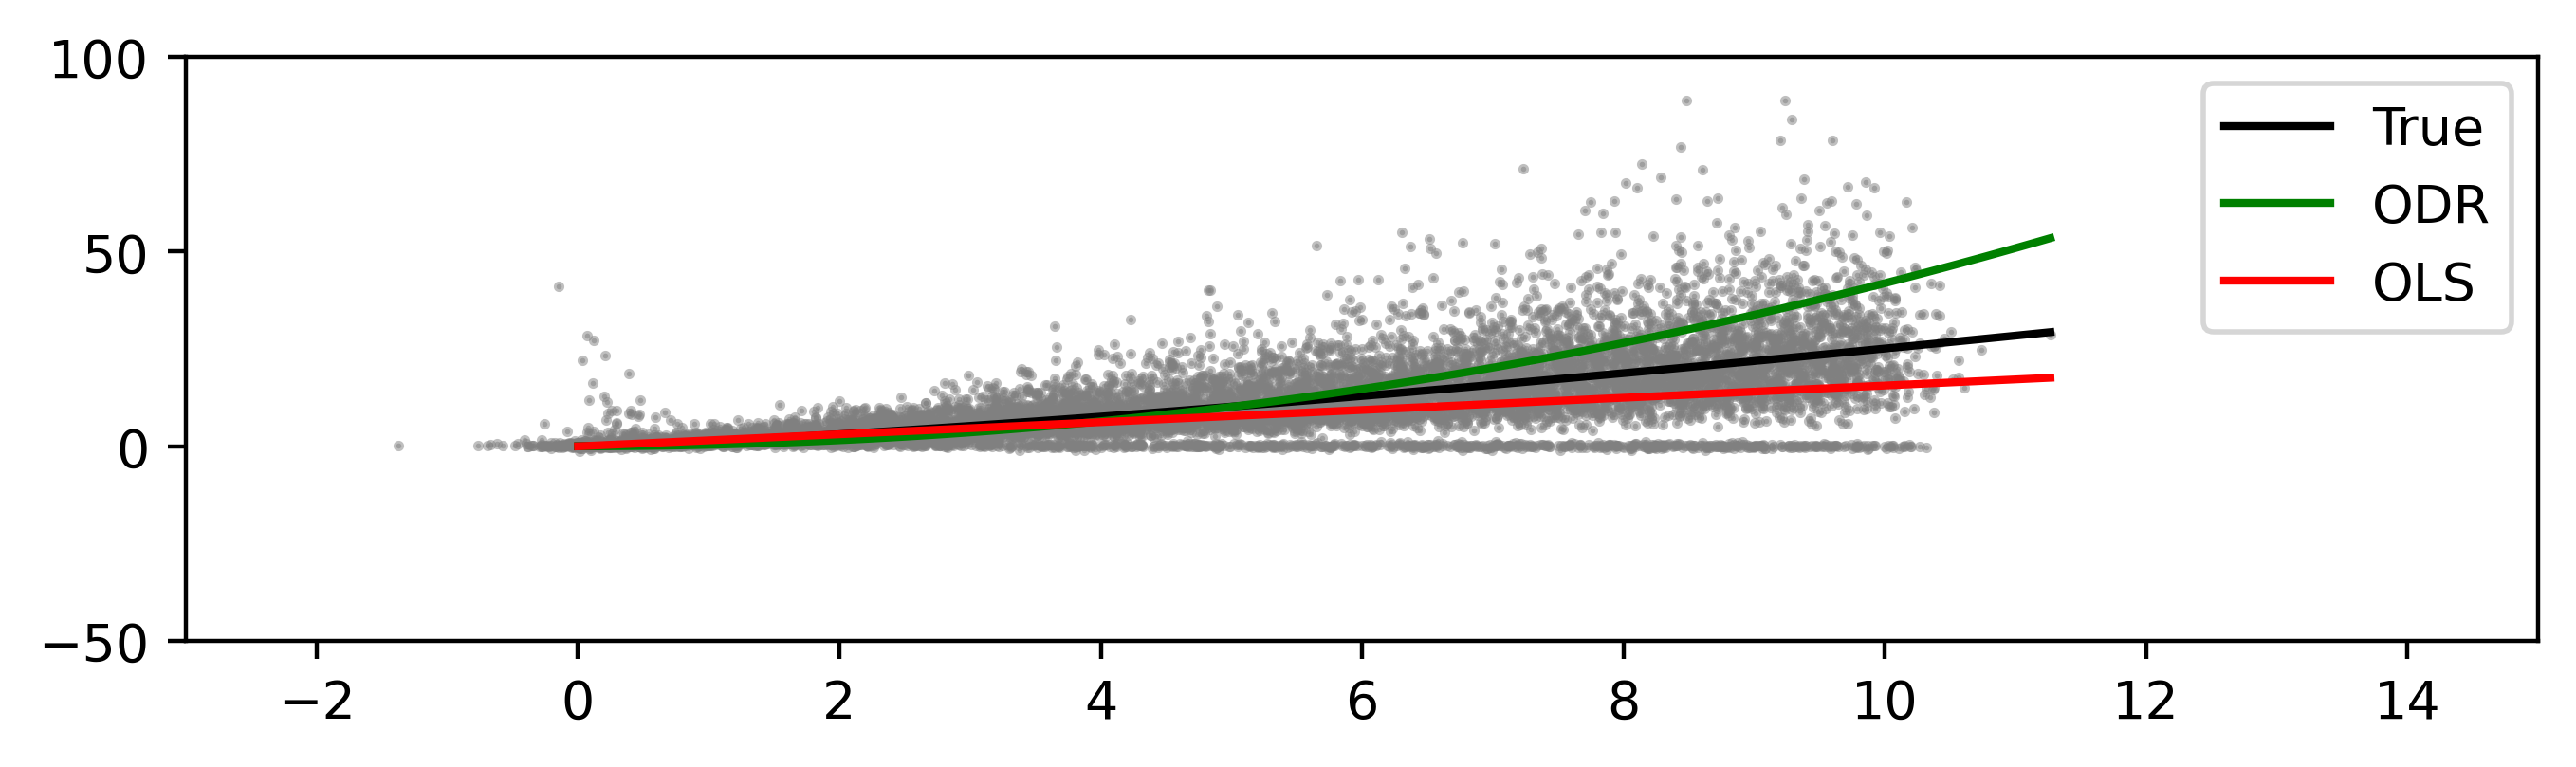

In [ ]:
plt.figure(figsize=(8, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10 ** (k * np.log10(xx) + b)
yy_ODR = 10 ** res_ODR['func_xy'](np.log10(xx))
yy_OLS = 10 ** res_OLS['func'](np.log10(xx))

plt.plot(xx, yy, color='black', label='True')
plt.plot(xx, yy_ODR, color='green', label='ODR')
plt.plot(xx, yy_OLS, color='red', label='OLS')

plt.legend()

plt.xlim(-3, 15)
plt.ylim(-50, 100)

### Fit p(x, x_err) and p(y, y_err)

In [ ]:
from raddest.api.flowvi import FlowVI
from raddest.api.fitter import LogLinearML, LogLinearKS, LogLinearStudentTML
from raddest.transfer import NegLogPlus

In [ ]:
xflow = FlowVI(x_min=0,
               x_max=x_obs.max(),
               x_err_min=0,
               x_err_max=x_err.max() * 1.2,
               transfer=NegLogPlus())

xflow.fit(x_obs, x_err, verbose=True)

100%|██████████| 100/100 [00:08<00:00, 11.90it/s]


step 0: loss 0.8807641267776489
step 10: loss 0.8603516221046448
step 20: loss 0.8571052551269531
step 30: loss 0.8544519543647766
step 40: loss 0.8522661924362183
step 50: loss 0.8535922765731812
step 60: loss 0.8530905246734619


In [ ]:
xflow.ks_test(x_obs, x_err, N=10000)

(0.015250018797814846, 0.43537253795647707)

In [ ]:
yflow = FlowVI(x_min=0,
               x_max=y_obs.max(),
               x_err_min=0,
               x_err_max=y_err.max() * 1.2,
               transfer=NegLogPlus())

yflow.fit(y_obs, y_err, verbose=True)

100%|██████████| 100/100 [00:07<00:00, 12.84it/s]


step 0: loss 2.0095808506011963
step 10: loss 1.9344565868377686
step 20: loss 1.922869086265564
step 30: loss 1.9168157577514648
step 40: loss 1.914520025253296
step 50: loss 1.9131388664245605
step 60: loss 1.9209833145141602


In [ ]:
yflow.ks_test(y_obs, y_err, N=10000)

(0.013250014744699001, 0.6171598149362536)

### Normal Model

In [ ]:
logLinear_ML = LogLinearML(xflow, yflow)

In [ ]:
params_ml, params_std, cov = logLinear_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err, params_0=[1., 0., 0.1],
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)  # loss is log-likelihood/n_samples

0 1.0145245 0.018516373 0.1745318 -4.0689397
1000 1.1011777 0.08607335 0.48596558 -2.5162463
2000 1.1182086 0.07465296 0.48594496 -2.5158217
3000 1.1302223 0.0666262 0.4858174 -2.5156112
4000 1.1386989 0.060958043 0.4857534 -2.515506
5000 1.1446851 0.05695157 0.48572236 -2.5154533
6000 1.1489177 0.054118 0.48570883 -2.5154274
7000 1.1519104 0.05211288 0.48570275 -2.5154145
8000 1.1540284 0.05069383 0.48569995 -2.5154078
9000 1.1555302 0.049689434 0.4856986 -2.5154045
converged, so stop with 9000 iterations


In [ ]:
print('ML fitted:', *params_ml)
print('Truth:', k, b, sig)

ML fitted: 1.1555302 0.049689434 0.4856986
Truth: 1.3 0.1 0.2


### T Model

In [ ]:
logLinear_studentT_ML = LogLinearStudentTML(xflow, yflow)

In [ ]:
params_ml_t, params_std_t, cov_t = logLinear_studentT_ML.fit(
    x_obs,
    x_err,
    y_obs,
    y_err, params_0=[1., 0., 2., 0.1],
    kde_batch_size=None,  # set it to 100000 or less if OOM
    verbose=True)  # loss is log-likelihood/n_samples

0 1.0033605 0.004580998 1.9996864 0.110347636 -3.1202505
1000 1.241207 0.1296584 1.965708 0.18490937 -2.1780772
2000 1.2836933 0.09970407 1.9319209 0.18292503 -2.1740582
3000 1.3015549 0.08716458 1.8992612 0.18158107 -2.1724856
4000 1.309207 0.08188808 1.8678172 0.18036745 -2.1714032
5000 1.3125069 0.07971263 1.8376243 0.17920448 -2.170472
6000 1.3139286 0.07887302 1.8087081 0.17808022 -2.169634
7000 1.3145328 0.07860836 1.781095 0.176994 -2.16887
8000 1.3147901 0.078585975 1.7548051 0.17594811 -2.168176
9000 1.3148997 0.07866231 1.7298511 0.17494425 -2.1675522


In [ ]:
print('ML fitted:', *params_ml_t)
print('Truth:', k, b, sig)

ML fitted: 1.3149136 0.07879582 1.7062618 0.17398496
Truth: 1.3 0.1 0.2


In [ ]:
q_16, q_84 = stuent_t.ppf([0.16, 0.84],
                          float(params_ml_t[-2]),
                          scale=float(params_ml_t[-1]))
(q_84 - q_16) / 2

0.2405854102467639

### KS

In [ ]:
logLinear_KS = LogLinearKS(xflow, yflow)

In [ ]:
params_mean, params_std, res_arr = logLinear_KS.fit(
    x_obs,
    y_obs,
    params_list=[
        np.linspace(0.5, 1.5, 7),
        np.linspace(-0.1, 0.3, 7),
        np.linspace(0.1, 0.3, 5)
    ],
    verbose=True)
print(params_mean, params_std)

----
k: 1.402 +/- 0.129
b: -0.038 +/- 0.079
sig: 0.263 +/- 0.043
----
k: 1.408 +/- 0.142
b: -0.053 +/- 0.103
sig: 0.305 +/- 0.070
----
k: 1.415 +/- 0.144
b: -0.061 +/- 0.102
sig: 0.313 +/- 0.071
----
k: 1.416 +/- 0.152
b: -0.056 +/- 0.106
sig: 0.316 +/- 0.070
----
k: 1.410 +/- 0.160
b: -0.052 +/- 0.115
sig: 0.309 +/- 0.067
----
k: 1.405 +/- 0.159
b: -0.046 +/- 0.113
sig: 0.311 +/- 0.073
----
k: 1.422 +/- 0.161
b: -0.057 +/- 0.116
sig: 0.301 +/- 0.067
----
k: 1.428 +/- 0.154
b: -0.064 +/- 0.112
sig: 0.304 +/- 0.072
----
k: 1.419 +/- 0.141
b: -0.056 +/- 0.102
sig: 0.315 +/- 0.070
----
k: 1.409 +/- 0.149
b: -0.051 +/- 0.105
sig: 0.306 +/- 0.067
----
k: 1.402 +/- 0.133
b: -0.046 +/- 0.096
sig: 0.314 +/- 0.067
max iteration reached
[ 1.40306332 -0.0459481   0.31524575] [0.13910486 0.09966109 0.06878615]


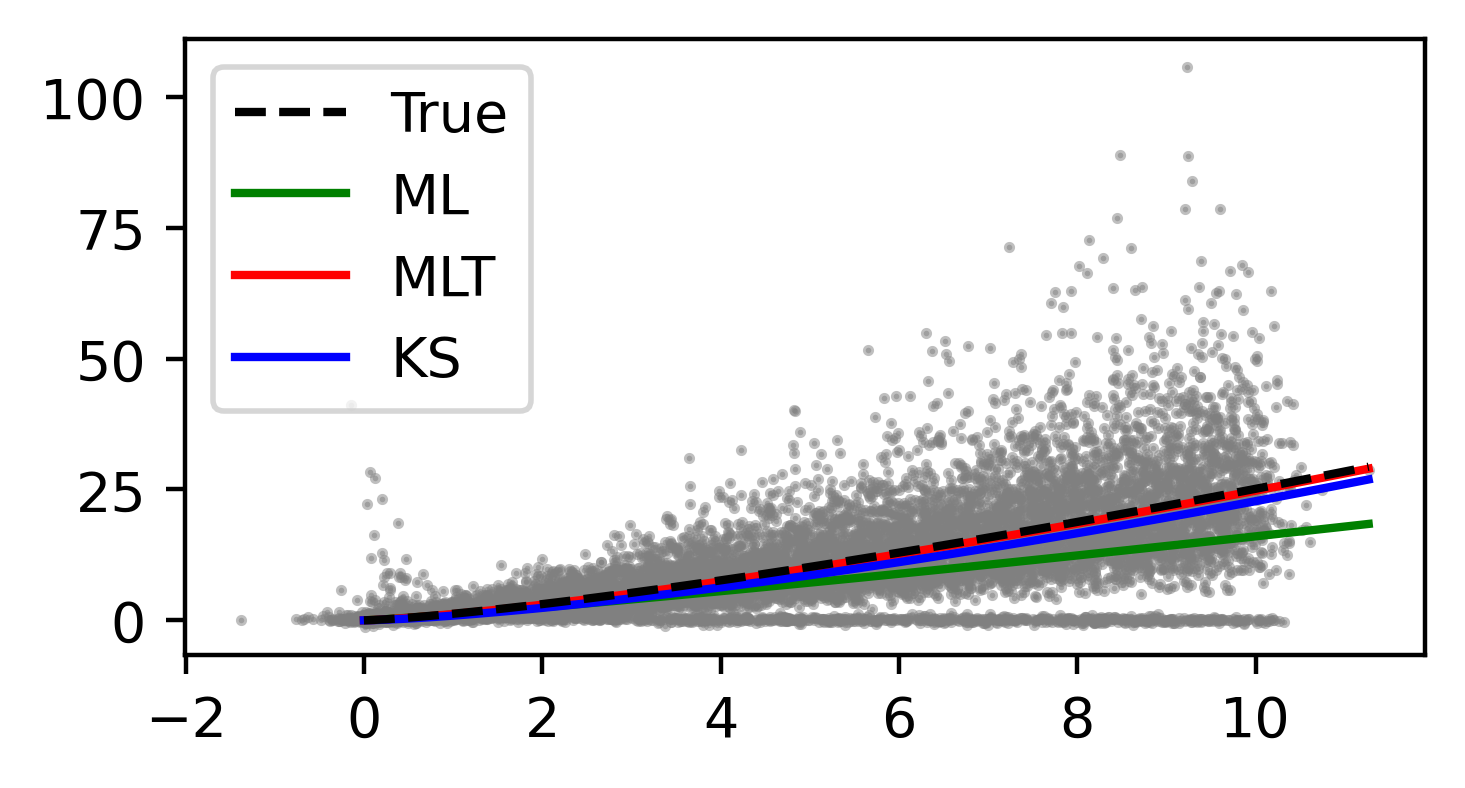

In [ ]:
plt.figure(figsize=(4, 2), dpi=400)

plt.scatter(x_obs, y_obs, s=1, color='gray', alpha=0.5)
xx = np.linspace(max(1e-10, x_obs.min()), x_obs.max(), 100)
yy = 10**(k * np.log10(xx) + b)
yy_ML = 10**(params_ml[0] * np.log10(xx) + params_ml[1])
yy_MLT = 10**(params_ml_t[0] * np.log10(xx) + params_ml_t[1])
yy_KS = 10**(params_mean[0] * np.log10(xx) + params_mean[1])

plt.plot(xx, yy, color='black', label='True', zorder=10, linestyle='--')
plt.plot(xx, yy_ML, color='green', label='ML')
plt.plot(xx, yy_MLT, color='red', label='MLT')
plt.plot(xx, yy_KS, color='blue', label='KS')

plt.legend()